<a href="https://colab.research.google.com/github/codebyjuveria/AI-Mini-Projects./blob/main/LinearRegressionMP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# upload the data
df = pd.read_csv('/content/AB_NYC_2019.csv (1).zip')

In [3]:
# understand the data
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [8]:
df.shape

(48895, 16)

In [9]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [12]:
# The typical target variable for this dataset is 'price'.
target_variable = df['price']
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [13]:
df.shape

(48895, 16)

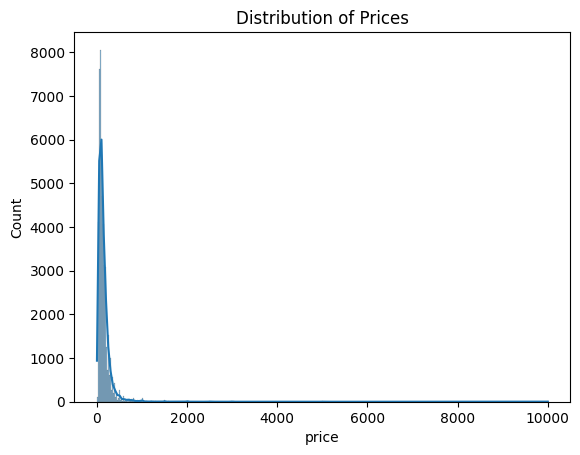

In [15]:
# Univariate Analysis
sns.histplot(df["price"], kde=True)
plt.title("Distribution of Prices")
plt.show()

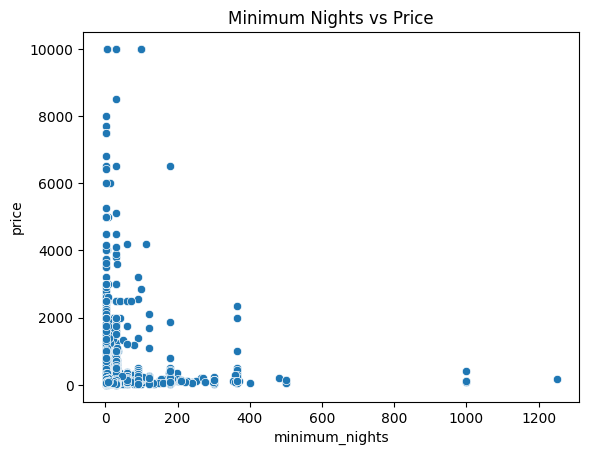

In [17]:
# Bivariate Analysis
sns.scatterplot(data=df, x="minimum_nights", y="price")
plt.title("Minimum Nights vs Price")
plt.show()

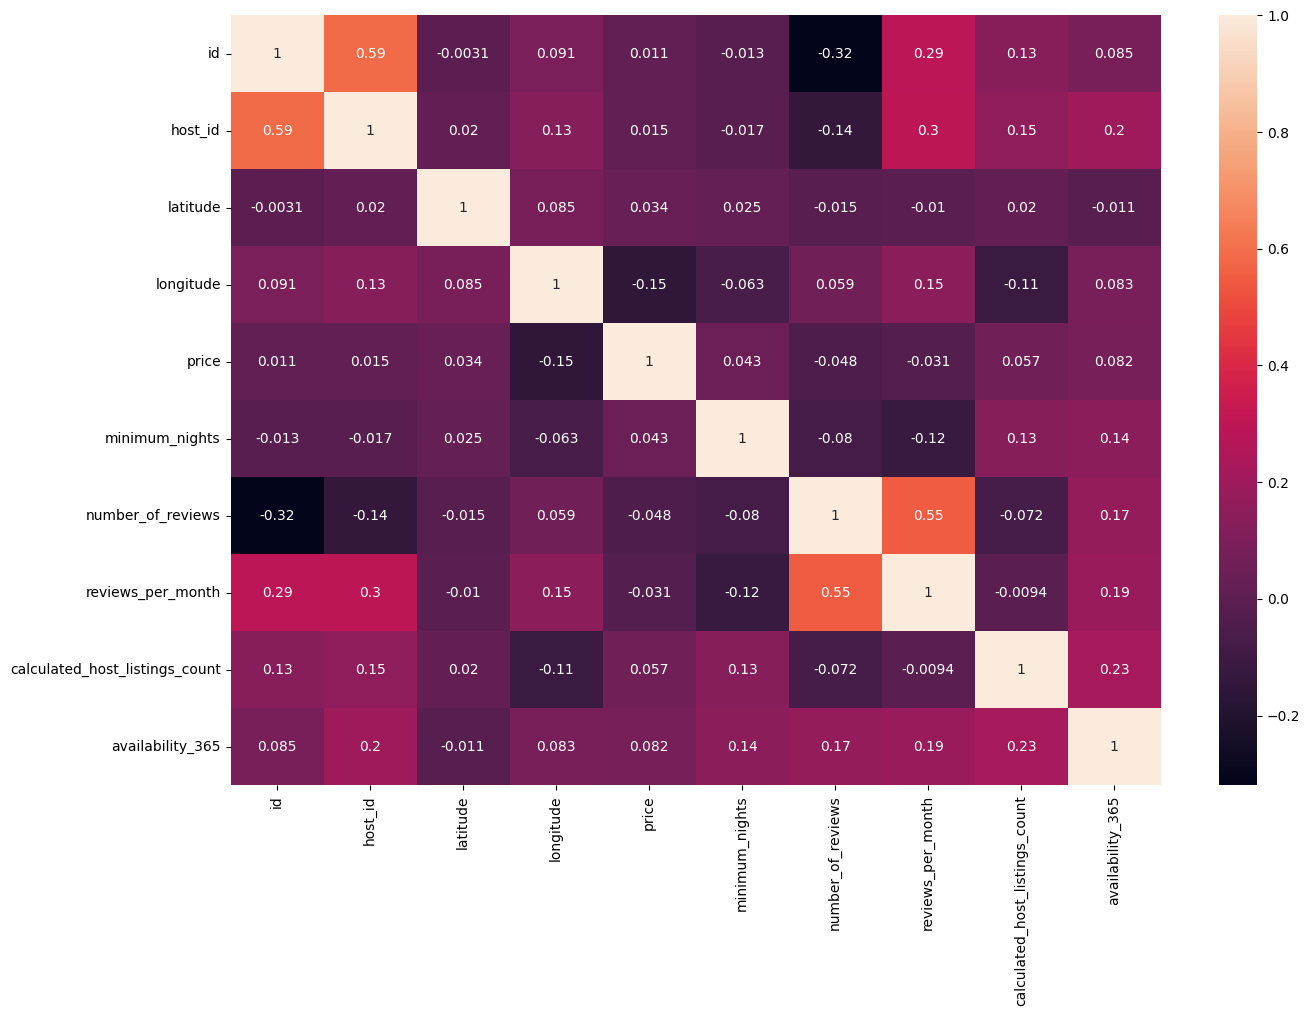

In [19]:
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

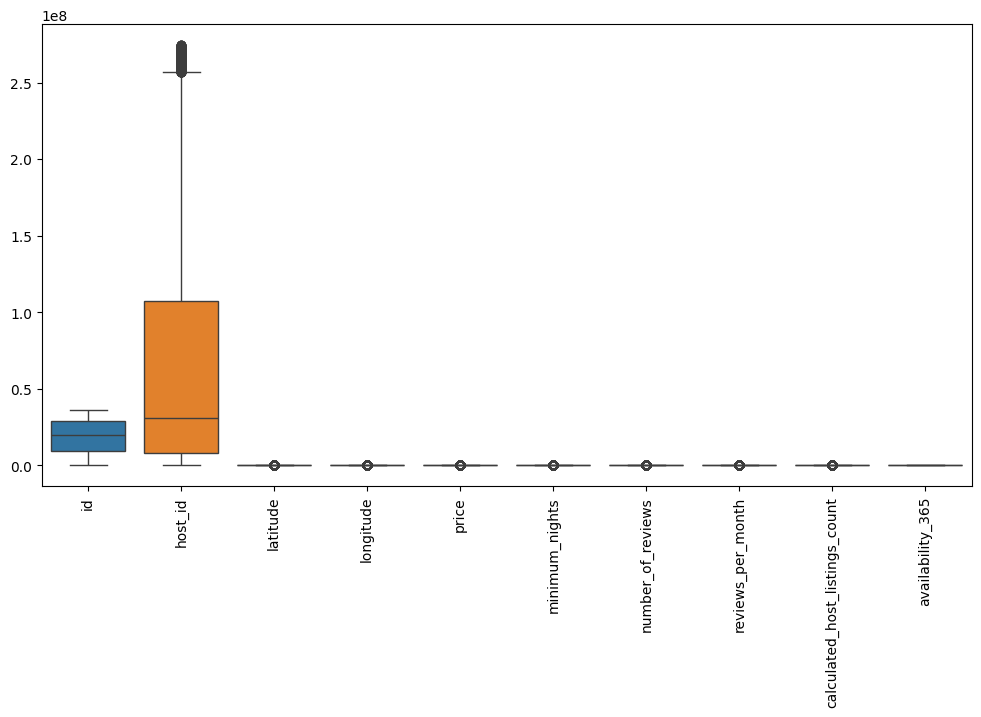

In [20]:
# outlier prediction
plt.figure(figsize= (12,6))
sns.boxplot(data = df)
plt.xticks(rotation = 90)
plt.show()

In [22]:
# Outlier Treatment
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_limit = Q1 - 1.5 * IQR
  upper_limit = Q3 + 1.5 * IQR
  df[col] = np.where(df[col] > upper_limit, upper_limit, np.where(df[col] < lower_limit, lower_limit, df[col]))

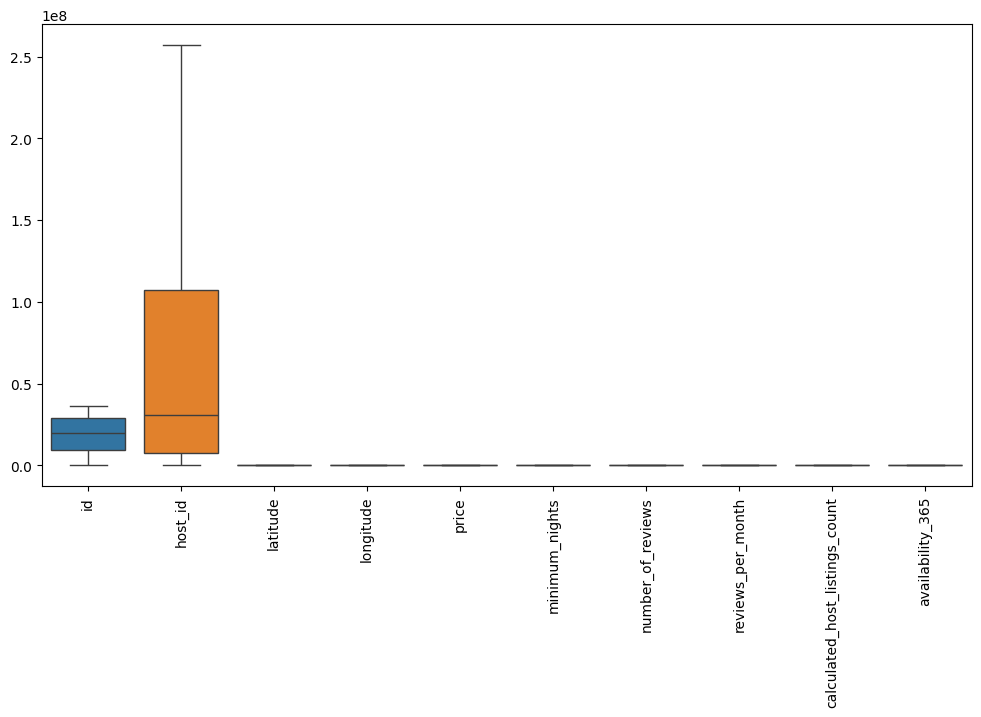

In [23]:
# outlier prediction- Recheck
plt.figure(figsize= (12,6))
sns.boxplot(data = df)
plt.xticks(rotation = 90)
plt.show()

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  float64
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  float64
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  float64
 10  minimum_nights                  48895 non-null  float64
 11  number_of_reviews               48895 non-null  float64
 12  last_review                     

In [26]:
# divide the data using the correct target variable ('price') for the NYC Airbnb dataset
X = df.drop(columns=["price"])
y = df["price"]

In [27]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [28]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(39116, 15)
(9779, 15)
(39116,)
(9779,)


In [29]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [32]:
# Select only numeric columns to train the model
numeric_cols = X_train.select_dtypes(include=[np.number]).columns

# Fill missing values (NaNs) in the selected numeric features with 0
X_train_clean = X_train[numeric_cols].fillna(0)

# Fit the linear regression model
model.fit(X_train_clean, y_train)

LinearRegression()

In [34]:
# Select the same numeric columns used during training
numeric_cols = X_train.select_dtypes(include=[np.number]).columns

# Prepare clean versions of train and test sets (fill NaNs with 0)
X_train_clean = X_train[numeric_cols].fillna(0)
X_test_clean = X_test[numeric_cols].fillna(0)

# Score using the matching numeric feature sets
print("Training Score:", model.score(X_train_clean, y_train))
print("Testing Score:", model.score(X_test_clean, y_test))

Training Score: 0.18236014060403616
Testing Score: 0.1748250290328346


In [35]:
model.intercept_

np.float64(-72360.30794953372)

In [36]:
model.coef_

array([ 1.81706851e-07,  1.63433086e-08,  1.83880423e+02, -8.79019854e+02,
       -5.65668501e-01, -2.20485195e-01, -7.78571855e-01, -9.63799802e+00,
        1.25671959e-01])

In [38]:
# Use X_test_clean which contains only the matching numeric features and has missing values handled
y_pred = model.predict(X_test_clean)
print(y_pred[:5])

[140.22226842  90.80870073 161.40750323 188.1594012  118.25875468]


In [39]:
results = pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
results.head()

,Actual,Predicted
879,89.0,140.222268
44383,30.0,90.808701
15394,120.0,161.407503
43230,334.0,188.159401
16332,199.0,118.258755


In [40]:
#Metrics

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

print("MAE:",mean_absolute_error(y_test,y_pred))

print("MSE:",mean_squared_error(y_test,y_pred))

print("R2 Square:",r2_score(y_test,y_pred))

MAE: 58.940555598813226
MSE: 5676.004391489966
R2 Square: 0.1748250290328346


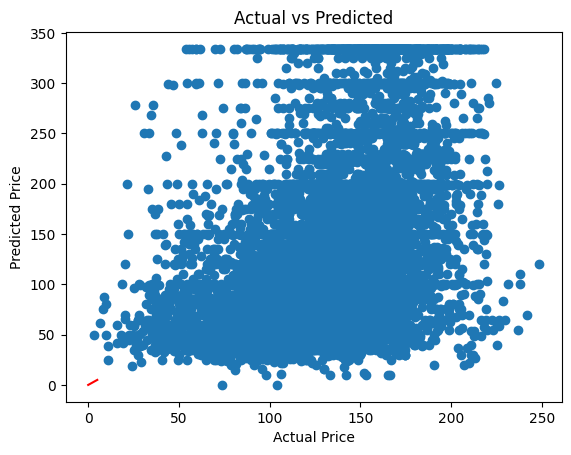

In [41]:
plt.scatter(y_pred,y_test)

plt.plot([0,5],[0,5], color = "red")

plt.xlabel("Actual Price")

plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted")

plt.show()

In [43]:
# Real test with an actual NYC Airbnb sample

# Create a mock listing using the correct numeric columns from the NYC Airbnb dataset
new_listing = pd.DataFrame({
    'id': [2539.0],
    'host_id': [2787.0],
    'latitude': [40.64749],
    'longitude': [-73.97237],
    'minimum_nights': [1.0],
    'number_of_reviews': [9.0],
    'reviews_per_month': [0.21],
    'calculated_host_listings_count': [6.0],
    'availability_365': [365.0]
})

# Align features to match the exact numeric column order used during training
new_listing = new_listing[X_train_clean.columns]

# Predict using the trained linear regression model
predictions = model.predict(new_listing)

print("The predicted price is:", predictions[0])

The predicted price is: 122.48087714255962


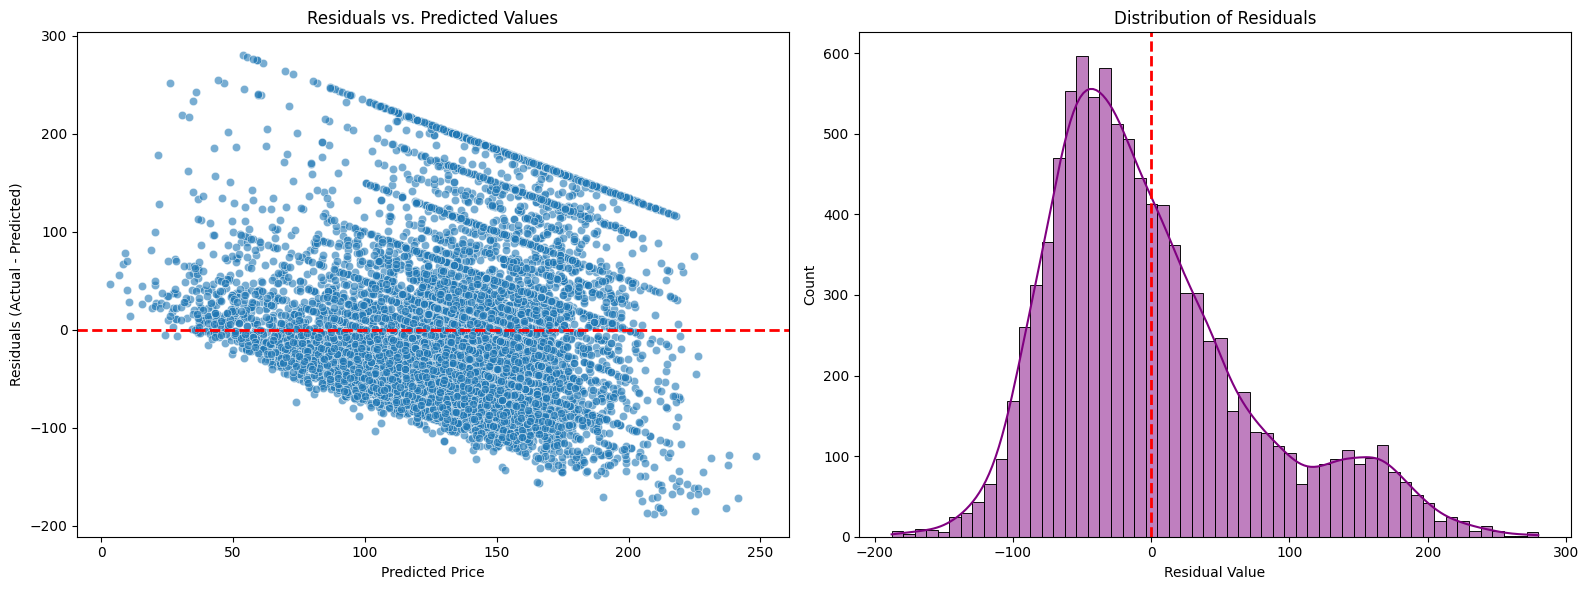

In [44]:
# Calculate residuals (Actual - Predicted)
residuals = y_test - y_pred

# Create a side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Residual Plot (Residuals vs Predicted Values)
sns.scatterplot(x=y_pred, y=residuals, ax=axes[0], alpha=0.6)
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_xlabel("Predicted Price")
axes[0].set_ylabel("Residuals (Actual - Predicted)")
axes[0].set_title("Residuals vs. Predicted Values")

# 2. Error Distribution Histogram
sns.histplot(residuals, kde=True, ax=axes[1], color='purple')
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel("Residual Value")
axes[1].set_ylabel("Count")
axes[1].set_title("Distribution of Residuals")

plt.tight_layout()
plt.show()